# Setup

In [1]:
!nvidia-smi

Sun Oct 25 13:09:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P0             44W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')


import os
DRIVE_ROOT = '/content/drive/MyDrive/stylessp'
CKPT_DIR   = f'{DRIVE_ROOT}/checkpoints'
HF_CACHE = '/content/hf_cache'
REPO_DIR   = '/content/StyleSSP'

for d in [DRIVE_ROOT, CKPT_DIR, HF_CACHE]:
    os.makedirs(d, exist_ok=True)


os.environ['HF_HOME'] = HF_CACHE

Mounted at /content/drive


fresh copy for every session

In [3]:

!rm -rf {REPO_DIR}
!git clone https://github.com/Michael-Boat-2/StyleSSP {REPO_DIR}
%cd {REPO_DIR}
!git log --oneline -1


Cloning into '/content/StyleSSP'...
remote: Enumerating objects: 124, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 124 (delta 27), reused 41 (delta 17), pack-reused 65 (from 1)
Receiving objects: 100% (124/124), 3.34 MiB | 58.91 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/StyleSSP
c621465 (HEAD -> main, origin/main, origin/HEAD) ablation setup


Installing Pinned Libraries

In [4]:
!pip install -q uv
!uv venv /content/venv --python 3.9
!uv pip install --python /content/venv/bin/python -r requirements.txt setuptools==69.5.1 datasets==2.21.0
!uv pip install --python /content/venv/bin/python git+https://github.com/openai/CLIP.git

!/content/venv/bin/python -c "import torch, diffusers, transformers; print('torch', torch.__version__, '| cuda', torch.cuda.is_available(), '| diffusers', diffusers.__version__, '| transformers', transformers.__version__)"

Using CPython 3.9.25
Creating virtual environment at: /content/venv
Activate with: source /content/venv/bin/activate
Using Python 3.9.25 environment at: /content/venv
Resolved 108 packages in 615ms
Prepared 108 packages in 24.97s
Installed 108 packages in 212ms
 + accelerate==0.33.0
 + aiohappyeyeballs==2.6.1
 + aiohttp==3.13.5
 + aiosignal==1.4.0
 + async-timeout==5.0.1
 + attrs==26.1.0
 + certifi==2024.7.4
 + cffi==1.17.0
 + charset-normalizer==3.3.2
 + contourpy==1.3.0
 + controlnet-aux==0.0.9
 + cycler==0.12.1
 + datasets==2.21.0
 + diffusers==0.30.0
 + dill==0.3.8
 + distlib==0.4.4
 + einops==0.8.0
 + entrypoints==0.4.2
 + executing==2.0.1
 + filelock==3.15.4
 + fonttools==4.54.0
 + frozenlist==1.8.0
 + fsspec==2024.6.1
 + ftfy==6.2.3
 + hf-transfer==0.1.8
 + huggingface-hub==0.24.5
 + idna==3.7
 + imageio==2.35.1
 + importlib-metadata==8.2.0
 + importlib-resources==6.4.5
 + jinja2==3.1.4
 + joblib==1.4.2
 + jupyter-client==7.4.9
 + jupyter-core==5.8.1
 + kiwisolver==1.4.7
 + lazy

In [ ]:

!/content/venv/bin/python repro/sample_data.py --out {DRIVE_ROOT}/data --cache {DRIVE_ROOT}/data/cache


Saved 10 content and 10 style images.


Downloading Checkpoints

In [5]:
from huggingface_hub import snapshot_download, hf_hub_download
import os

def have(path):
    return os.path.exists(path) and os.path.getsize(path) > 0



# IP-Adapter:  SDXL weights file for style injection during sampling
if not have(f'{CKPT_DIR}/IP-Adapter/sdxl_models/ip-adapter_sdxl_vit-h.safetensors'):
    snapshot_download('h94/IP-Adapter', local_dir=f'{CKPT_DIR}/IP-Adapter',
                      allow_patterns=['sdxl_models/ip-adapter_sdxl_vit-h.safetensors'])

# ControlNets (control_type = 'tile_canny' in config.py) : content preservation during sampling
if not os.path.exists(f'{CKPT_DIR}/controlnet-tile-sdxl-1.0/config.json'):
    snapshot_download('xinsir/controlnet-tile-sdxl-1.0', local_dir=f'{CKPT_DIR}/controlnet-tile-sdxl-1.0',
                      allow_patterns=['config.json', '*.safetensors'])

if not os.path.exists(f'{CKPT_DIR}/MistoLine/config.json'):
    snapshot_download('TheMistoAI/MistoLine', local_dir=f'{CKPT_DIR}/MistoLine',
                      allow_patterns=['config.json', '*.fp16.safetensors'])

# IP-Adapter-Instruct: the content/style extractor behind negative guidance
if not have(f'{CKPT_DIR}/models/ip-adapter-instruct-sdxl.bin'):
    hf_hub_download('CiaraRowles/IP-Adapter-Instruct', 'ip-adapter-instruct-sdxl.bin',
                    local_dir=f'{CKPT_DIR}/models')


!mkdir -p /content/checkpoints && cp -rn {DRIVE_ROOT}/checkpoints/. /content/checkpoints/
!ln -sfn /content/checkpoints {REPO_DIR}/checkpoints
!du -sh /content/checkpoints/*

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
2.4G	/content/checkpoints/controlnet-tile-sdxl-1.0
667M	/content/checkpoints/IP-Adapter
2.4G	/content/checkpoints/MistoLine
2.0G	/content/checkpoints/models


In [10]:
!ls /content/venv/bin/python /content/checkpoints /content/drive/MyDrive/stylessp

/content/venv/bin/python

/content/checkpoints:
controlnet-tile-sdxl-1.0  IP-Adapter  MistoLine  models

/content/drive/MyDrive/stylessp:
checkpoints	  data	    ours_c07_s00.png	    runs
colab_freeze.txt  hf_cache  ours_content_style.png  test_images


In [9]:
%%time
!/content/venv/bin/python repro/run_ablation.py --data {DRIVE_ROOT}/data --out {DRIVE_ROOT}/runs

100 pairs x 4 configs, seed 1234
Phase A: 98 of 100 pairs still to invert
Some kwargs in processor config are unused and will not have any effect: num_query_tokens. 

Keyword arguments {'safety_checker': None} are not expected by StableDiffusionXLPipelineExtraCFG and will be ignored.

dict_keys(['latents', 'proj_in.weight', 'proj_in.bias', 'proj_new_input.weight', 'proj_new_input.bias', 'proj_prompt_input.weight', 'proj_prompt_input.bias', 'proj_out.weight', 'proj_out.bias', 'norm_out.weight', 'norm_out.bias', 'layers.0.0.norm1.weight', 'layers.0.0.norm1.bias', 'layers.0.0.norm2.weight', 'layers.0.0.norm2.bias', 'layers.0.0.to_q.weight', 'layers.0.0.to_kv.weight', 'layers.0.0.to_out.weight', 'layers.0.1.0.weight', 'layers.0.1.0.bias', 'layers.0.1.1.weight', 'layers.0.1.3.weight', 'layers.1.0.norm1.weight', 'layers.1.0.norm1.bias', 'layers.1.0.norm2.weight', 'layers.1.0.norm2.bias', 'layers.1.0.to_q.weight', 'layers.1.0.to_kv.weight', 'layers.1.0.to_out.weight', 'layers.1.1.0.weight', '

In [11]:
import os
d = f'{DRIVE_ROOT}/runs/seed1234'
print('latents:', len(os.listdir(f'{d}/latents')))
for c in ['baseline', 'fm', 'ng', 'full']:
    print(c, len(os.listdir(f'{d}/images/{c}')))

latents: 100
baseline 100
fm 100
ng 100
full 100


In [12]:
!/content/venv/bin/python repro/run_ablation.py --data {DRIVE_ROOT}/data --out {DRIVE_ROOT}/runs --seed 42

100 pairs x 4 configs, seed 42
Phase A: 100 of 100 pairs still to invert
Some kwargs in processor config are unused and will not have any effect: num_query_tokens. 

Keyword arguments {'safety_checker': None} are not expected by StableDiffusionXLPipelineExtraCFG and will be ignored.

dict_keys(['latents', 'proj_in.weight', 'proj_in.bias', 'proj_new_input.weight', 'proj_new_input.bias', 'proj_prompt_input.weight', 'proj_prompt_input.bias', 'proj_out.weight', 'proj_out.bias', 'norm_out.weight', 'norm_out.bias', 'layers.0.0.norm1.weight', 'layers.0.0.norm1.bias', 'layers.0.0.norm2.weight', 'layers.0.0.norm2.bias', 'layers.0.0.to_q.weight', 'layers.0.0.to_kv.weight', 'layers.0.0.to_out.weight', 'layers.0.1.0.weight', 'layers.0.1.0.bias', 'layers.0.1.1.weight', 'layers.0.1.3.weight', 'layers.1.0.norm1.weight', 'layers.1.0.norm1.bias', 'layers.1.0.norm2.weight', 'layers.1.0.norm2.bias', 'layers.1.0.to_q.weight', 'layers.1.0.to_kv.weight', 'layers.1.0.to_out.weight', 'layers.1.1.0.weight', 'l

In [7]:
#negatuve guidance effect, sanity check

import numpy as np
from PIL import Image
d = f'{DRIVE_ROOT}/runs/seed1234/images'
for name in ['c00_s00', 'c00_s01']:
    a = np.asarray(Image.open(f'{d}/baseline/{name}.png'), dtype=float)
    for cfg in ['fm', 'ng', 'full']:
        b = np.asarray(Image.open(f'{d}/{cfg}/{name}.png'), dtype=float)
        print(name, cfg, 'mean abs diff vs baseline:', round(np.abs(a - b).mean(), 2))

c00_s00 fm mean abs diff vs baseline: 27.56
c00_s00 ng mean abs diff vs baseline: 1.77
c00_s00 full mean abs diff vs baseline: 27.54
c00_s01 fm mean abs diff vs baseline: 47.46
c00_s01 ng mean abs diff vs baseline: 1.54
c00_s01 full mean abs diff vs baseline: 47.58


Recording the used environment for the reproduction

In [ ]:
!mkdir -p {REPO_DIR}/repro/env
!/content/venv/bin/python --version > {REPO_DIR}/repro/env/colab_freeze.txt
!uv pip freeze --python /content/venv/bin/python >> {REPO_DIR}/repro/env/colab_freeze.txt
!cp {REPO_DIR}/repro/env/colab_freeze.txt {DRIVE_ROOT}/colab_freeze.txt
!head -5 {DRIVE_ROOT}/colab_freeze.txt


Using Python 3.9.25 environment at: /content/venv


In [ ]:
# test pair for our config

CONTENT = f'{DRIVE_ROOT}/data/content/c07.jpg'
STYLE   = f'{DRIVE_ROOT}/data/style/s09.jpg'

!sed -i "s|style_image_dir = .*|style_image_dir = '{STYLE}'|" src/config.py
!sed -i "s|content_image_dir = .*|content_image_dir = '{CONTENT}'|" src/config.py
!grep -n "image_dir" src/config.py

66:    style_image_dir = '/content/drive/MyDrive/stylessp/data/style/s00.jpg'
67:    content_image_dir = '/content/drive/MyDrive/stylessp/data/content/c07.jpg'


In [ ]:
%%time
!/content/venv/bin/python infer_style.py

Some kwargs in processor config are unused and will not have any effect: num_query_tokens. 

Keyword arguments {'safety_checker': None} are not expected by StableDiffusionXLPipelineExtraCFG and will be ignored.

dict_keys(['latents', 'proj_in.weight', 'proj_in.bias', 'proj_new_input.weight', 'proj_new_input.bias', 'proj_prompt_input.weight', 'proj_prompt_input.bias', 'proj_out.weight', 'proj_out.bias', 'norm_out.weight', 'norm_out.bias', 'layers.0.0.norm1.weight', 'layers.0.0.norm1.bias', 'layers.0.0.norm2.weight', 'layers.0.0.norm2.bias', 'layers.0.0.to_q.weight', 'layers.0.0.to_kv.weight', 'layers.0.0.to_out.weight', 'layers.0.1.0.weight', 'layers.0.1.0.bias', 'layers.0.1.1.weight', 'layers.0.1.3.weight', 'layers.1.0.norm1.weight', 'layers.1.0.norm1.bias', 'layers.1.0.norm2.weight', 'layers.1.0.norm2.bias', 'layers.1.0.to_q.weight', 'layers.1.0.to_kv.weight', 'layers.1.0.to_out.weight', 'layers.1.1.0.weight', 'layers.1.1.0.bias', 'layers.1.1.1.weight', 'layers.1.1.3.weight', 'layers.

results/ours_c07_s00.png


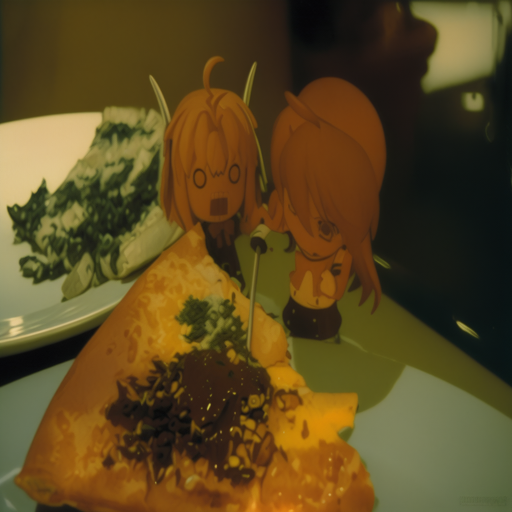

In [ ]:
from IPython.display import display
from PIL import Image
import glob, shutil

for p in sorted(glob.glob('results/*.png')):
    print(p)
    display(Image.open(p).resize((512, 512)))
    shutil.copy(p, f'{DRIVE_ROOT}/')